In [ ]:
import pandas as pd

df = pd.read_csv("/content/sample_data/train.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
print(df.shape)

(891, 12)


In [ ]:
print(df.columns)


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
print("Mean Age =", df["Age"].mean())
print("Mean Fare =", df["Fare"].mean())

print("Median Age =", df["Age"].median())
print("Median Fare =", df["Fare"].median())

print("Mode of Embarked:")
print(df["Embarked"].mode())
print("Mode of Sex:")
print(df["Sex"].mode())

Mean Age = 29.69911764705882
Mean Fare = 32.204207968574636
Median Age = 28.0
Median Fare = 14.4542
Mode of Embarked:
0    S
Name: Embarked, dtype: object
Mode of Sex:
0    male
Name: Sex, dtype: object


In [ ]:
# Check missing values
df.isnull().sum()

# Percentage of missing values
(df.isnull().sum()/len(df))*100

# Fill missing Age values with Median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing Embarked values with Mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Drop Cabin column
# df = df.drop(columns=["Cabin"])

# Verify no missing values remain
df.isnull().sum()

KeyError: "['Cabin'] not found in axis"

In [ ]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
df["Survived"] = df["Survived"].astype("category")

df["Pclass"] = df["Pclass"].astype("category")

In [ ]:
df.dtypes

,0
PassengerId,int64
Survived,category
Pclass,category
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
df["Sex"] = df["Sex"].map({
    "male": 0,
    "female": 1
})

df["Sex"].head()

,Sex
0,0
1,1
2,1
3,1
4,0


In [ ]:
print(df["Embarked"].unique())

['S' 'C' 'Q']


In [ ]:
df = pd.get_dummies(
    df,
    columns=["Embarked"],
    drop_first=True,
    dtype=int
)

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,0,0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,0,1
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,0,1


In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df[["Age", "Fare"]] = scaler.fit_transform(df[["Age", "Fare"]])

df[["Age", "Fare"]].head()

,Age,Fare
0,0.271174,0.014151
1,0.472229,0.139136
2,0.321438,0.015469
3,0.434531,0.103644
4,0.434531,0.015713


In [ ]:
print(df["Age"].min())
print(df["Age"].max())

print(df["Fare"].min())
print(df["Fare"].max())

0.0
1.0
0.0
1.0


In [ ]:
# Calculate Q1 and Q3
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)

Q1 = 0.01544007251587456
Q3 = 0.060507970265993034
IQR = 0.04506789775011848


In [ ]:
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

Lower Limit = -0.05216177410930315
Upper Limit = 0.12810981689117074


In [ ]:
outliers = df[(df["Fare"] < lower_limit) | (df["Fare"] > upper_limit)]

print("Number of Outliers =", len(outliers))

Number of Outliers = 116


In [ ]:
outliers

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_Q,Embarked_S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,0.472229,1,0,PC 17599,0.139136,0,0
27,28,0,1,"Fortune, Mr. Charles Alexander",0,0.233476,3,2,19950,0.513342,0,1
31,32,1,1,"Spencer, Mrs. William Augustus (Marie Eugenie)",1,0.346569,1,0,PC 17569,0.285990,0,0
34,35,0,1,"Meyer, Mr. Edgar Joseph",0,0.346569,1,0,PC 17604,0.160387,0,0
52,53,1,1,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",1,0.610455,1,0,PC 17572,0.149765,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
846,847,0,3,"Sage, Mr. Douglas Bullen",0,0.346569,8,2,CA. 2343,0.135753,0,1
849,850,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",1,0.346569,1,0,17453,0.173920,0,0
856,857,1,1,"Wick, Mrs. George Dennick (Mary Hitchcock)",1,0.560191,1,1,36928,0.321798,0,1
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",1,0.346569,8,2,CA. 2343,0.135753,0,1


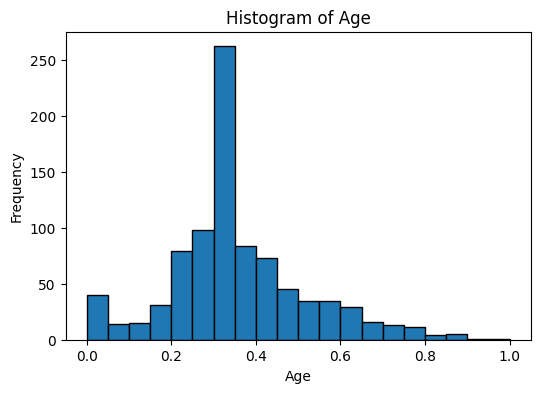

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.hist(df["Age"], bins=20, edgecolor="black")

plt.title("Histogram of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

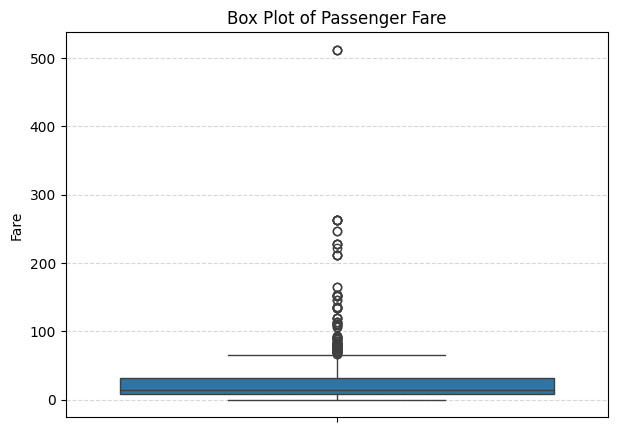

In [ ]:
df_original = pd.read_csv("/content/sample_data/train.csv")
plt.figure(figsize=(7,5))

sns.boxplot(y=df_original["Fare"])

plt.title("Box Plot of Passenger Fare")
plt.ylabel("Fare")

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

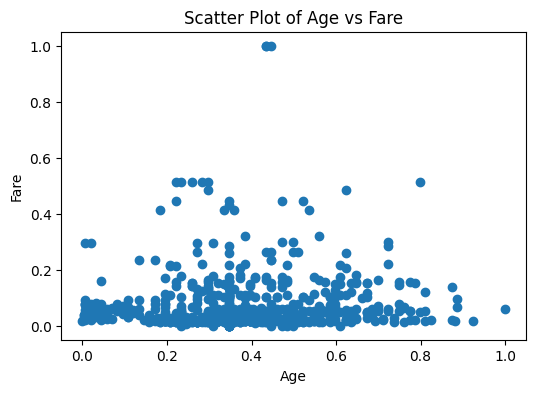

In [ ]:
plt.figure(figsize=(6,4))

plt.scatter(df["Age"], df["Fare"])

plt.title("Scatter Plot of Age vs Fare")
plt.xlabel("Age")
plt.ylabel("Fare")

plt.show()